In [1]:
# Data Inspection & Cleaning 
import pandas as pd 
import numpy as np 

In [2]:
# Load a row data 
df = pd.read_csv('github_intelligence_data.csv')

In [3]:
# Check the first 5 rows of the dataset
df.head()

,Repository,Stars,Forks,Open Issues,Primary Language,Last Updated
0,pandas,50146,20531,2179,Python,2026-10-17T16:59:22Z
1,requests,54472,13115,244,Python,2026-10-17T17:05:14Z
2,react,251207,51513,1458,JavaScript,2026-10-17T17:04:15Z
3,vue,212628,33675,639,TypeScript,2026-10-17T16:38:02Z
4,spring-framework,60294,38754,506,Java,2026-10-17T15:31:27Z


In [4]:
# Check the shape of the dataset (rows and columns count)
print("Dataset Shape:", df.shape)

Dataset Shape: (12, 6)


In [5]:
# Check data types and non-null values
df.info()

# Summary statistics for numerical columns
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Repository        12 non-null     str  
 1   Stars             12 non-null     int64
 2   Forks             12 non-null     int64
 3   Open Issues       12 non-null     int64
 4   Primary Language  12 non-null     str  
 5   Last Updated      12 non-null     str  
dtypes: int64(3), str(3)
memory usage: 1.1 KB


,Stars,Forks,Open Issues
count,12.000000,12.000000,12.000000
mean,130173.000000,34518.500000,5250.666667
std,69923.713851,19243.713795,6613.269187
min,50146.000000,13115.000000,244.000000
25%,69160.500000,20134.750000,605.750000
50%,124388.000000,29898.000000,2694.500000
75%,195607.000000,46135.000000,7238.750000
max,251207.000000,79641.000000,21866.000000


In [6]:
# Check for any missing values in the dataset
df.isnull().sum()

Repository          0
Stars               0
Forks               0
Open Issues         0
Primary Language    0
Last Updated        0
dtype: int64

In [7]:
# Remove duplicate rows from the dataset
df = df.drop_duplicates()

In [8]:
df

,Repository,Stars,Forks,Open Issues,Primary Language,Last Updated
0,pandas,50146,20531,2179,Python,2026-10-17T16:59:22Z
1,requests,54472,13115,244,Python,2026-10-17T17:05:14Z
2,react,251207,51513,1458,JavaScript,2026-10-17T17:04:15Z
3,vue,212628,33675,639,TypeScript,2026-10-17T16:38:02Z
4,spring-framework,60294,38754,506,Java,2026-10-17T15:31:27Z
5,elasticsearch,78295,26121,6194,Java,2026-10-17T15:15:18Z
6,tensorflow,201076,79641,3382,C++,2026-10-17T17:16:43Z
7,protobuf,72116,16317,373,C++,2026-10-17T17:16:37Z
8,go,139282,22571,10373,Go,2026-10-17T17:06:27Z
9,kubernetes,128328,47287,3210,Go,2026-10-17T17:02:20Z


In [9]:
# Step 4: Exploratory Data Analysis (Key Insights)

In [10]:
# 1. Get the top programming languages by repository count
print("--- Top 5 Programming Languages ---")
top_languages = df['Primary Language'].value_counts().head(5)
print(top_languages)


--- Top 5 Programming Languages ---
Primary Language
Python        2
TypeScript    2
Java          2
C++           2
Go            2
Name: count, dtype: int64


In [11]:
# Average Stars & Forks by Language
language_stats = df.groupby('Primary Language')[['Stars', 'Forks']].mean().sort_values(by='Stars', ascending=False)
print(language_stats.head(5))


                     Stars    Forks
Primary Language                   
JavaScript        251207.0  51513.0
TypeScript        203206.0  39713.0
C++               136596.0  47979.0
Go                133805.0  34929.0
Rust              120448.0  18946.0


In [12]:
 # Most Starred Repository
top_repo_idx = df['Stars'].idxmax()
top_repo = df.loc[top_repo_idx]
print(f"\n🌟 Most Starred Repo: {top_repo['Repository']} with {top_repo['Stars']} stars!")


🌟 Most Starred Repo: react with 251207 stars!


In [13]:
# Visualizing EDA (Graphs) 

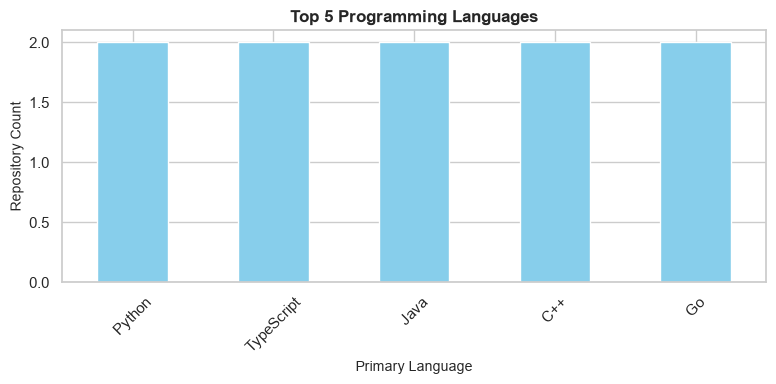

In [14]:
# Graph 1: Top 5 Languages Bar Chart

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 4))
top_languages.plot(kind='bar', color='skyblue')
plt.title('Top 5 Programming Languages', fontsize=12, fontweight='bold')
plt.xlabel('Primary Language', fontsize=10)
plt.ylabel('Repository Count', fontsize=10)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

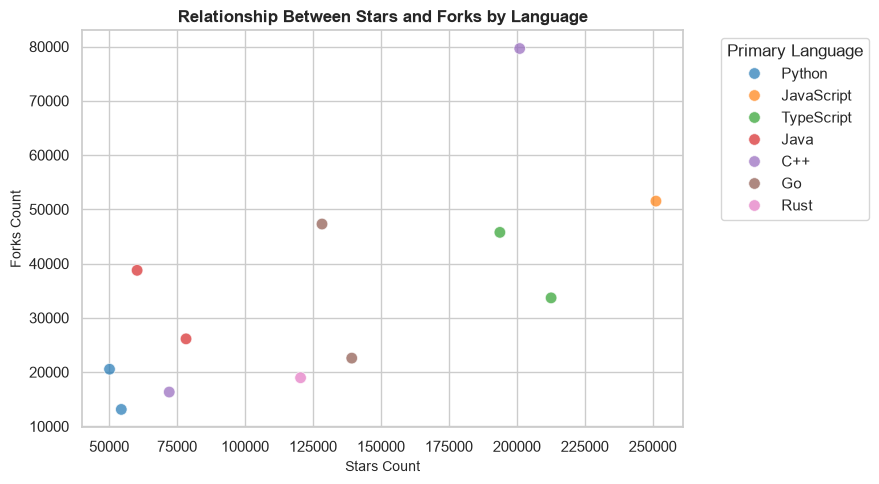

In [15]:
# Graph 2: Stars vs. Forks Scatter Plot

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df, 
    x='Stars', 
    y='Forks', 
    hue='Primary Language', 
    palette='tab10', 
    alpha=0.7, 
    s=70
)
plt.title('Relationship Between Stars and Forks by Language', fontsize=12, fontweight='bold')
plt.xlabel('Stars Count', fontsize=10)
plt.ylabel('Forks Count', fontsize=10)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Primary Language')
plt.tight_layout()
plt.show()

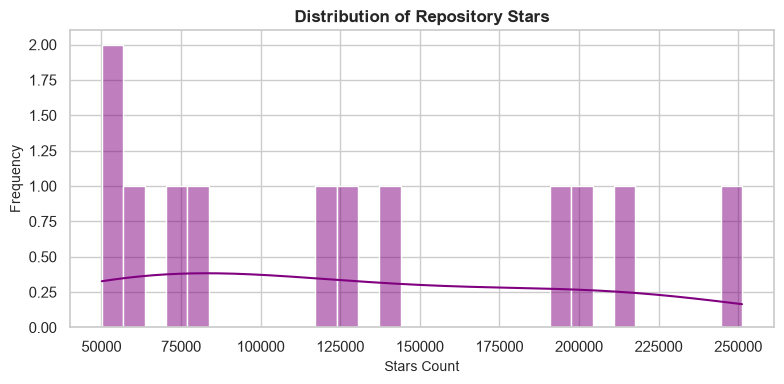

In [16]:
# Graph 3: Distribution of Repository Stars (Histogram)

plt.figure(figsize=(8, 4))
sns.histplot(df['Stars'], bins=30, kde=True, color='purple')
plt.title('Distribution of Repository Stars', fontsize=12, fontweight='bold')
plt.xlabel('Stars Count', fontsize=10)
plt.ylabel('Frequency', fontsize=10)
plt.tight_layout()